# Experiment 3: Breadth-first and depth-first search
One search function, two algorithms: the only difference is which end of the deque is popped.
The maze is carved by randomised DFS and then a few extra walls are removed so that more
than one route exists (in a perfect maze BFS and DFS would be forced onto the same path).

In [1]:
import json, os
from collections import deque
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

os.makedirs('figs', exist_ok=True)
mpl.rcParams.update({'font.family': 'serif', 'font.serif': ['Times New Roman', 'DejaVu Serif'],
                     'font.size': 10, 'axes.grid': True, 'grid.color': '0.88', 'grid.linewidth': 0.6,
                     'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 1.4,
                     'legend.frameon': False, 'savefig.dpi': 200, 'savefig.bbox': 'tight'})
C = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
R = {}

## 1. The maze as an implicit graph

In [2]:
def carve_maze(h_cells, w_cells, loops=0.08, seed=0):
    """Randomised-DFS carver on a (2h+1) x (2w+1) grid; 1 = wall, 0 = open.
    Afterwards a fraction `loops` of the remaining interior walls between two corridors is opened."""
    rng = np.random.default_rng(seed)
    H, W = 2*h_cells + 1, 2*w_cells + 1
    maze = np.ones((H, W), dtype=int)
    stack, seen = [(0, 0)], {(0, 0)}
    maze[1, 1] = 0
    while stack:
        r, c = stack[-1]
        nbrs = [(r+dr, c+dc) for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1))
                if 0 <= r+dr < h_cells and 0 <= c+dc < w_cells and (r+dr, c+dc) not in seen]
        if not nbrs:
            stack.pop(); continue
        nr, nc = nbrs[rng.integers(len(nbrs))]
        maze[2*r+1 + (nr-r), 2*c+1 + (nc-c)] = 0     # knock down the wall between
        maze[2*nr+1, 2*nc+1] = 0
        seen.add((nr, nc)); stack.append((nr, nc))
    walls = [(r, c) for r in range(1, H-1) for c in range(1, W-1) if maze[r, c] == 1 and
             ((maze[r-1, c] == 0 and maze[r+1, c] == 0 and maze[r, c-1] == 1 and maze[r, c+1] == 1) or
              (maze[r, c-1] == 0 and maze[r, c+1] == 0 and maze[r-1, c] == 1 and maze[r+1, c] == 1))]
    for k in rng.choice(len(walls), int(loops*len(walls)), replace=False):
        maze[walls[k]] = 0
    return maze

maze = carve_maze(11, 17, loops=0.08, seed=119608)   # 23 x 35 grid
H, W = maze.shape
START, GOAL = (1, 1), (H-2, W-2)
print('maze', H, 'x', W, '| open cells', int((maze == 0).sum()))

def neighbours(cell):
    r, c = cell
    for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):    # up, down, left, right
        nr, nc = r + dr, c + dc
        if 0 <= nr < H and 0 <= nc < W:                  # bounds first
            if maze[nr, nc] == 0:                        # then contents
                yield (nr, nc)

maze 23 x 35 | open cells 388


## 2. One function, two algorithms

In [3]:
def search(start, goal, mode='bfs'):
    frontier = deque([start])
    parent = {start: None}          # marks a cell as discovered when it is enqueued
    order, frontier_size = {}, []
    while frontier:
        node = frontier.popleft() if mode == 'bfs' else frontier.pop()   # THE ONLY DIFFERENCE
        order[node] = len(order)
        if node == goal:
            frontier_size.append(len(frontier)); break
        for nxt in neighbours(node):
            if nxt not in parent:
                parent[nxt] = node
                frontier.append(nxt)
        frontier_size.append(len(frontier))
    path, cur = [], goal
    if goal in parent:
        while cur is not None:
            path.append(cur); cur = parent[cur]
    return order, path[::-1], frontier_size

def validate(path):
    """Starts at START, ends at GOAL, every step is 4-adjacent and lands on an open cell."""
    ok = path[0] == START and path[-1] == GOAL
    for (r1, c1), (r2, c2) in zip(path, path[1:]):
        ok &= abs(r1 - r2) + abs(c1 - c2) == 1 and maze[r2, c2] == 0
    return bool(ok)

res = {}
for mode in ('bfs', 'dfs'):
    order, path, fr = search(START, GOAL, mode)
    res[mode] = dict(order=order, path=path, frontier=fr)
    R[mode] = dict(expanded=len(order), path_steps=len(path) - 1, path_cells=len(path),
                   valid=validate(path), max_frontier=max(fr))
    print(f"{mode.upper()}: {len(order)} expanded, path {len(path)-1} steps, valid={validate(path)}, max frontier {max(fr)}")
R['maze'] = dict(H=H, W=W, open=int((maze == 0).sum()))

# Independent check that BFS is shortest: plain BFS distance map from the start
dist = {START: 0}; q = deque([START])
while q:
    u = q.popleft()
    for v in neighbours(u):
        if v not in dist:
            dist[v] = dist[u] + 1; q.append(v)
R['true_shortest'] = dist[GOAL]
print('true shortest distance to goal:', dist[GOAL])

BFS: 364 expanded, path 68 steps, valid=True, max frontier 11
DFS: 89 expanded, path 84 steps, valid=True, max frontier 11
true shortest distance to goal: 68


## 3. Swapping the goal: does DFS always expand fewer cells?

In [4]:
rng = np.random.default_rng(1)
open_cells = [tuple(p) for p in np.argwhere(maze == 0)]
wins = 0; trials = 200
for k in rng.choice(len(open_cells), trials, replace=False):
    g = open_cells[k]
    wins += len(search(START, g, 'dfs')[0]) < len(search(START, g, 'bfs')[0])
R['dfs_fewer_random_goals'] = dict(wins=int(wins), trials=trials)
print(f'DFS expanded fewer cells than BFS for {wins} of {trials} random goals')

DFS expanded fewer cells than BFS for 99 of 200 random goals


## 4. Figures

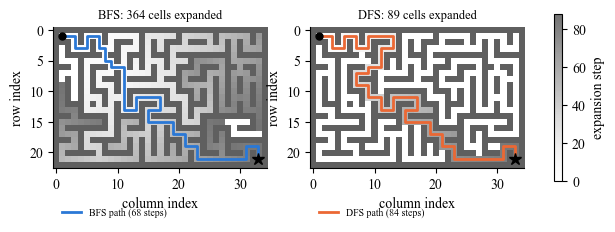

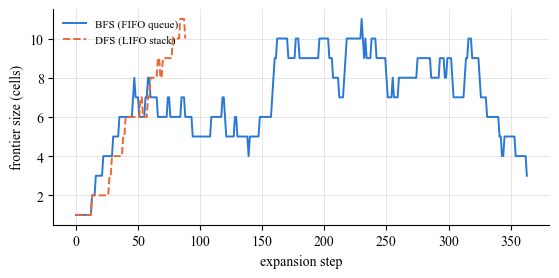

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(7.6, 2.9))
for ax, mode, col in zip(axes, ('bfs', 'dfs'), (C[0], C[1])):
    order, path = res[mode]['order'], res[mode]['path']
    grid = np.full(maze.shape, np.nan)
    for (r, c), k in order.items():
        grid[r, c] = k
    ax.imshow(maze, cmap='binary', vmin=0, vmax=1.6)
    im = ax.imshow(grid, cmap='Greys', alpha=0.55)
    ax.plot([c for _, c in path], [r for r, _ in path], color=col, lw=2.0,
            label=f'{mode.upper()} path ({len(path)-1} steps)')
    ax.plot(*START[::-1], 'o', color='k', ms=5); ax.plot(*GOAL[::-1], '*', color='k', ms=9)
    ax.set_title(f'{mode.upper()}: {len(order)} cells expanded', fontsize=9)
    ax.set_xlabel('column index'); ax.set_ylabel('row index'); ax.grid(False)
    ax.legend(loc='lower left', fontsize=7, bbox_to_anchor=(0, -0.42))
fig.colorbar(im, ax=axes, shrink=0.75, label='expansion step')
fig.savefig('figs/fig3_1_maze_paths.png'); plt.show()

fig, ax = plt.subplots(figsize=(6.4, 2.8))
ax.plot(res['bfs']['frontier'], color=C[0], label='BFS (FIFO queue)')
ax.plot(res['dfs']['frontier'], color=C[1], ls='--', label='DFS (LIFO stack)')
ax.set_xlabel('expansion step'); ax.set_ylabel('frontier size (cells)')
ax.legend(loc='upper left', fontsize=8)
fig.savefig('figs/fig3_2_frontier.png'); plt.show()

In [6]:
with open('results.json', 'w') as fh:
    json.dump(R, fh, indent=1)
print(json.dumps(R, indent=1))

{
 "bfs": {
  "expanded": 364,
  "path_steps": 68,
  "path_cells": 69,
  "valid": true,
  "max_frontier": 11
 },
 "dfs": {
  "expanded": 89,
  "path_steps": 84,
  "path_cells": 85,
  "valid": true,
  "max_frontier": 11
 },
 "maze": {
  "H": 23,
  "W": 35,
  "open": 388
 },
 "true_shortest": 68,
 "dfs_fewer_random_goals": {
  "wins": 99,
  "trials": 200
 }
}
